In [10]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict , Literal
from dotenv import load_dotenv
from langchain_groq import ChatGroq
import requests

import os

load_dotenv()

True

In [ ]:
#Initialize Groq
client = ChatGroq(model="openai/gpt-oss-20b",api_key=os.getenv("GROQ_API_KEY"))
prompt= input("Enter your linkedin post topic:")

#Define Graph State
class LinkedinState(TypedDict):
    topic: str
    post :str
    post_status: Literal["Success","Failed"] 
    post_id : str

In [12]:
def generate_post(state:LinkedinState):
    response=client.invoke(f"""
        You are a professional LinkedIn content writer.

        Write a natural, engaging LinkedIn post about this topic:
        {state['topic']}

        Requirements:
        - Use a professional but human tone.
        - Make the post engaging and easy to read.
        - Add relevant hashtags.
        - Do not invent facts.
        - Return only the LinkedIn post.
        """)
    return {'post':response.content}

In [13]:
def approve_post(state: LinkedinState):
    print("\n--- Review your LinkedIn post ---\n")
    print(state["post"])

    approval = input(
        "\nPublish this post to LinkedIn? (yes/no): "
    ).strip().lower()

    if approval == "yes":
        return {"post_status": "Approved"}

    return {"post_status": "Failed"}


In [14]:

# Publish post to LinkedIn
def publish_to_linkedin(state: LinkedinState):
    access_token = os.getenv("LINKEDIN_ACCESS_TOKEN")
    person_id = os.getenv("LINKEDIN_PERSON_ID")

    if not access_token or not person_id:
        print("Missing LinkedIn credentials.")
        return {
            "post_status": "Failed",
            "post_id": ""
        }

    # Official UGC Posts API endpoint
    url = "https://api.linkedin.com/v2/ugcPosts"

    headers = {
        "Authorization": f"Bearer {access_token}",
        "Content-Type": "application/json",
        "X-Restli-Protocol-Version": "2.0.0"
    }

    # Text-only LinkedIn post
    payload = {
        "author": f"urn:li:person:{person_id}",
        "lifecycleState": "PUBLISHED",
        "specificContent": {
            "com.linkedin.ugc.ShareContent": {
                "shareCommentary": {
                    "text": state["post"]
                },
                "shareMediaCategory": "NONE"
            }
        },
        "visibility": {
            "com.linkedin.ugc.MemberNetworkVisibility": "PUBLIC"
        }
    }

    try:
        response = requests.post(
            url,
            headers=headers,
            json=payload,
            timeout=30
        )

        if response.status_code != 201:
            print("LinkedIn API error:", response.status_code)
            print(response.text)

            return {
                "post_status": "Failed",
                "post_id": ""
            }

        post_id = response.headers.get("X-RestLi-Id", "")

        print("\nLinkedIn post published successfully!")
        print("Post ID:", post_id)

        return {
            "post_status": "Success",
            "post_id": post_id
        }

    except requests.RequestException as error:
        print("Network error:", error)

        return {
            "post_status": "Failed",
            "post_id": ""
        }


In [15]:
graph_builder = StateGraph(LinkedinState)
graph_builder.add_node("generate_post", generate_post)
graph_builder.add_node("approve_post", approve_post)
graph_builder.add_node("publish_to_linkedin", publish_to_linkedin)

graph_builder.add_edge(START, "generate_post")
graph_builder.add_edge("generate_post", "approve_post")

graph_builder.add_conditional_edges(
    "approve_post",
    lambda state: (
        "publish_to_linkedin"
        if state["post_status"] == "Approved"
        else END
    ),
    {
        "publish_to_linkedin": "publish_to_linkedin",
        END: END
    }
)

graph_builder.add_edge("publish_to_linkedin", END)

graph = graph_builder.compile()





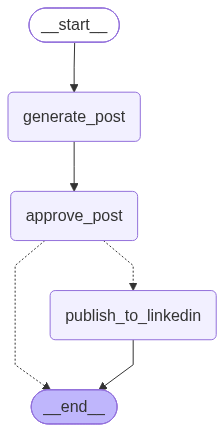

In [16]:
graph

In [17]:
result = graph.invoke({
    "topic": prompt,
    "post": "",
    "post_status": "Failed",
    "post_id": ""
})

print("\nFinal status:", result["post_status"])


--- Review your LinkedIn post ---

🚀 **Generative AI: The New Creative Catalyst**

Generative AI isn’t just a buzzword—it’s reshaping how we prototype, design, and even write. From auto‑generating marketing copy to drafting code snippets, these models are turning raw data into actionable insights and creative assets in a fraction of the time it used to take.

Key takeaways:
- **Speed & Scale** – Generate drafts, mock‑ups, or data visualizations almost instantly.
- **Personalization at Scale** – Tailor content to individual users without the manual overhead.
- **Collaboration Boost** – Teams can iterate faster, focusing on strategy rather than repetitive tasks.

But with great power comes responsibility. Ethical use, bias mitigation, and transparent governance are essential to ensure these tools add value without unintended consequences.

What’s your experience with generative AI? Have you seen it transform your workflow or product? Share your stories below—I’d love to hear how it’s ch

In [8]:
import os
import requests
from dotenv import load_dotenv

load_dotenv()

token = os.getenv("LINKEDIN_ACCESS_TOKEN")

response = requests.get(
    "https://api.linkedin.com/v2/userinfo",
    headers={"Authorization": f"Bearer {token}"},
    timeout=30
)

print("Status:", response.status_code)
print(response.text)

Status: 200
{"sub":"sw5T8mhRUt","email_verified":true,"name":"Abhay Singh","locale":{"country":"US","language":"en"},"given_name":"Abhay","family_name":"Singh","email":"2k23.csai2310286@gmail.com","picture":"https://media.licdn.com/dms/image/v2/D4E03AQFWrcWURrZleg/profile-displayphoto-shrink_200_200/B4EZZQ3d_oHYAc-/0/1745113442207?e=1793836800&v=beta&t=WcI6wevOvZuW3CudxC2FKbQyrjx_KBEBlfSfnpBuFjU"}
